# ANN演示
使用sklearn中手写数字集进行ANN演示

**依赖包：**
```
python
sklearn
torch
torchvision
matplotlib
```

**知识点：**  
[Pytorch nn.Module的基本使用](https://blog.csdn.net/zhaohongfei_358/article/details/122797244)  
[Pytorch nn.Linear的基本用法](https://blog.csdn.net/zhaohongfei_358/article/details/122797190)  
[PytorchVision Transforms的基本使用](https://blog.csdn.net/zhaohongfei_358/article/details/122799782)  
[Pytorch中DataLoader的基本用法](https://blog.csdn.net/zhaohongfei_358/article/details/122742656)  
[Pytorch详解NLLLoss和CrossEntropyLoss](https://blog.csdn.net/qq_22210253/article/details/85229988)  
[如何确定神经网络的层数和隐藏层神经元数量](https://zhuanlan.zhihu.com/p/100419971)  
## 1 数据集信息

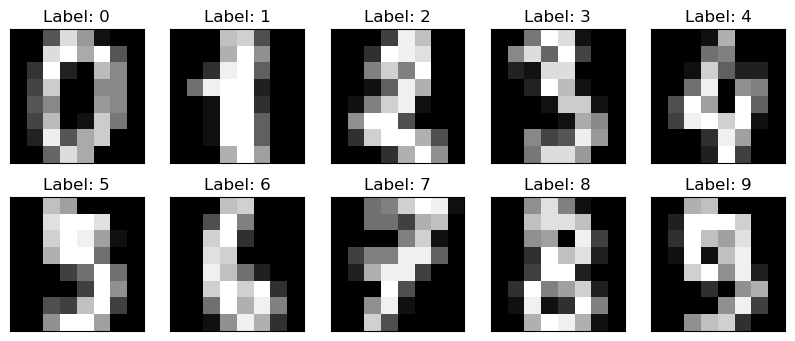

In [8]:
import matplotlib.pyplot as plt
from sklearn import datasets

# 加载手写数字数据集
digits = datasets.load_digits()  # digits 数据集：1797 张 8x8 灰度手写数字图，标签为 0~9

# 设置图像的大小
plt.figure(figsize=(10, 4))

# 显示前10个样本
for i in range(10):
    # 在子图中显示图像
    plt.subplot(2, 5, i + 1)  # 2行5列的子图
    plt.imshow(digits.images[i], cmap='gray')  # 显示图像
    plt.title('Label: %i' % digits.target[i])  # 显示标签
    plt.xticks([])  # 隐藏x轴刻度
    plt.yticks([])  # 隐藏y轴刻度

# 显示图像
plt.show()

In [43]:
# 查看数据集信息
print(digits.keys())       # 数据集包含的字段：data/images/target 等
print(digits.data.shape)   # 特征矩阵：(样本数, 64)，每张 8x8 图展平成 64 维向量
print(digits.images.shape) # 图像数组：(样本数, 8, 8)
print(digits.target.shape) # 标签数组：(样本数,)，取值 0~9

dict_keys(['data', 'target', 'frame', 'feature_names', 'target_names', 'images', 'DESCR'])
(1797, 64)
(1797, 8, 8)
(1797,)


In [5]:
digits.images[0]  # 第 0 个样本的 8x8 二维像素矩阵（元素为 0~16 的灰度值）

array([[ 0.,  0.,  5., 13.,  9.,  1.,  0.,  0.],
       [ 0.,  0., 13., 15., 10., 15.,  5.,  0.],
       [ 0.,  3., 15.,  2.,  0., 11.,  8.,  0.],
       [ 0.,  4., 12.,  0.,  0.,  8.,  8.,  0.],
       [ 0.,  5.,  8.,  0.,  0.,  9.,  8.,  0.],
       [ 0.,  4., 11.,  0.,  1., 12.,  7.,  0.],
       [ 0.,  2., 14.,  5., 10., 12.,  0.,  0.],
       [ 0.,  0.,  6., 13., 10.,  0.,  0.,  0.]])

In [41]:
digits.data[0]  # 第 0 个样本展平后的 64 维特征向量（即上面 images 的一维形式）

array([ 0.,  0.,  5., 13.,  9.,  1.,  0.,  0.,  0.,  0., 13., 15., 10.,
       15.,  5.,  0.,  0.,  3., 15.,  2.,  0., 11.,  8.,  0.,  0.,  4.,
       12.,  0.,  0.,  8.,  8.,  0.,  0.,  5.,  8.,  0.,  0.,  9.,  8.,
        0.,  0.,  4., 11.,  0.,  1., 12.,  7.,  0.,  0.,  2., 14.,  5.,
       10., 12.,  0.,  0.,  0.,  0.,  6., 13., 10.,  0.,  0.,  0.])

**从上可知digits.images是一个8x8的二维数组，而digits.data是digits.images展开的一维形式。**

## 2 ANN
### 2.1 数据加载及标准化

In [47]:
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
# 提示：特征缩放应在“数据集划分之后”进行（见下方 markdown 思考题），否则测试集信息会提前泄露

# 加载手写数字数据集
digits = datasets.load_digits()

# 特征数据和目标标签
X = digits.data        # 形状 (1797, 64)：每张 8x8 图像展平成 64 维特征
y = digits.target      # 标签：0~9 共 10 类

# 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)  # 80%/20% 划分；固定 random_state 保证可复现。必须先划分数据、再只在训练集上做标准化（见下方），避免测试集信息提前泄露

# 特征缩放
scaler = StandardScaler()   # 标准化：按特征列做 (x-均值)/标准差
X_train = scaler.fit_transform(X_train)  # 只在训练集上 fit 学习均值/方差
X_test = scaler.transform(X_test)     # 测试集用训练集学到的均值/方差变换，避免数据泄露

**思考**：为啥此处的StandardScaler特征缩放应该在数据集划分之后(先划分再缩放)？ 

### 2.2 ANN训练并预测
#### 2.2.1 使用MLPClassifier  

MLPClassifier 是 scikit-learn 库中的一个多层感知器（Multilayer Perceptron）分类器。它通过堆叠多个全连接层（也称为密集层）来学习数据中的复杂模式。  
MLPClassifier 的一些常用参数包括：  
- hidden_layer_sizes：一个元组，定义了每个隐藏层的神经元数量。
- max_iter：最大迭代次数。
-  alpha：L2 正则化系数。
-  solver：优化算法，可选的有 'lbfgs'、'sgd' 和 'adam'。
-  verbose：如果设置为大于 0 的值，则在训练过程中输出日志。
-  random_state：随机数生成器的种子，用于初始化权重。
-  learning_rate_init：初始学习率。

MLPClassifier的用法与Marchine Learning中的SVM，RF，KNN等模型类似。  

In [82]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

# 创建神经网络分类器。 
mlp = MLPClassifier(hidden_layer_sizes=(124, 64), max_iter=300, alpha=1e-4,  # 两个隐藏层：124 和 64 个神经元
                    solver='sgd', verbose=10, random_state=42,  # sgd 优化器；verbose 打印训练过程；alpha 为 L2 正则化系数
                    learning_rate_init=.1)  # 初始学习率 0.1

# 训练模型
mlp.fit(X_train, y_train)

# 预测
y_pred = mlp.predict(X_test)

# 评估模型
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

Iteration 1, loss = 1.81951705
Iteration 2, loss = 0.53249651
Iteration 3, loss = 0.19704426
Iteration 4, loss = 0.11292689
Iteration 5, loss = 0.06599078
Iteration 6, loss = 0.03868122
Iteration 7, loss = 0.02188247
Iteration 8, loss = 0.01455084
Iteration 9, loss = 0.00975084
Iteration 10, loss = 0.00744124
Iteration 11, loss = 0.00612906
Iteration 12, loss = 0.00530058
Iteration 13, loss = 0.00462613
Iteration 14, loss = 0.00414772
Iteration 15, loss = 0.00379766
Iteration 16, loss = 0.00344754
Iteration 17, loss = 0.00320376
Iteration 18, loss = 0.00300974
Iteration 19, loss = 0.00281349
Iteration 20, loss = 0.00263166
Iteration 21, loss = 0.00249725
Iteration 22, loss = 0.00235128
Iteration 23, loss = 0.00224698
Iteration 24, loss = 0.00216420
Iteration 25, loss = 0.00204529
Iteration 26, loss = 0.00195672
Iteration 27, loss = 0.00187197
Iteration 28, loss = 0.00179774
Iteration 29, loss = 0.00173041
Iteration 30, loss = 0.00167981
Iteration 31, loss = 0.00161015
Iteration 32, los

#### 2.2.2 使用SVM

In [53]:
from sklearn.svm import SVC

# 创建SVM分类器
svm_model = SVC(gamma=0.0001, C=100.)  # gamma：RBF 核宽度（越小边界越平滑）；C：正则化强度的倒数（越大越拟合训练集）

# 训练模型
svm_model.fit(X_train, y_train)

# 预测
y_pred = svm_model.predict(X_test)

# 评估模型
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.9806


#### 2.2.3 使用pytorch自定义ANN

In [ ]:
from tqdm import tqdm
import torch.nn as nn
import torch.optim as optim
import copy

def run(model, dataloader, device, epoch, criterion=nn.CrossEntropyLoss(), optimizer=None, training=False):   
    """执行一个 epoch 的前向计算（training=True 时含反向传播），返回 (准确率, 平均损失)。"""
    total_size = 0
    total_loss = 0.0
    correct = 0

    for images, labels in tqdm(dataloader, desc=f"Epoch {epoch}", unit="batch"):
        images, labels = images.to(device), labels.to(device)        

        # 下面几行代码顺序不影响执行结果正确性。
        outputs = model(images)                # 前向传播：得到各类别得分 logits
        loss = criterion(outputs, labels)              # 交叉熵损失
        if training:
            optimizer.zero_grad()               # 清空上一步残留的梯度
            loss.backward()                    # 反向传播计算梯度
            optimizer.step()                   # 按梯度更新模型参数
        
        total_loss += loss.item() * labels.size(0)  # loss 是 batch 平均值，乘以样本数再累加，便于最后求全局平均
        total_size += labels.size(0)
        _, predicted = torch.max(outputs, 1)   # 取得分最大的类别索引作为预测结果
        correct += (predicted == labels).sum().item()  # 累计预测正确的样本数
        
    return correct/total_size, total_loss/total_size


def run_epoch(model, dataloader, device, epoch=0, criterion=nn.CrossEntropyLoss(), optimizer=None, training=False):
    """按 training 标志执行训练或评估的一个 epoch，返回 (准确率, 平均损失)。"""
    acc, loss = 0, 0
    if training:
        model.train()   # 训练模式：启用 Dropout/BatchNorm 的训练期行为
        acc, loss = run(model, dataloader, device, epoch, optimizer=optimizer, criterion=criterion, training=True)
    else:
        model.eval()    # 评估模式：固定 Dropout/BatchNorm 行为
        with torch.no_grad():  # 由于是eval, 因此使用"无梯度"上下文(好处是中间不会自动进行梯度跟踪计算，速度快省内存)
            acc, loss = run(model, dataloader, device, epoch, optimizer=optimizer, criterion=criterion, training=False)

    return acc, loss


def train(model, device, train_loader, valid_loader, **kwargs):
    """
    Args:
      model: 模型
      device: 运行设备(CPU/GPU)
      train_loader: train数据集加载器(从该loader中获取train datasets)
      valid_loader: valid数据集加载器
      kwargs: 其它的参数, 字典形式传入的额外参数。 比如下面的"模型参数"应由外部通过此参数传入，而不是写死。当前暂没有用。
    """
    # 定义损失函数和优化器
    criterion = nn.CrossEntropyLoss()  # 多分类交叉熵损失（内部已含 softmax）
    optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)  # Adam 优化器，学习率 1e-4
    
    # 模型参数
    num_epochs = 300  # 定义一个足够大的训练轮次
    num_patience = 10  # 定义耐心值，即验证集准确率不再提高的轮次

    patience_count = 0  # 记录验证集准确率不再提高的轮次
    best_accuracy = 0.0
    best_loss = 0.0
    best_model = None
    best_epoch = 0
    
    trains = []  # 保存train阶段的结果值
    valids = []  # 保存valid阶段的结果值
    for epoch in range(num_epochs):
        # 每轮先在训练集上训练，再到验证集上评估（评估不更新参数）
        train_acc, train_loss = run_epoch(model, train_loader, device, epoch, criterion=criterion, optimizer=optimizer, training=True)
        valid_acc, valid_loss = run_epoch(model, valid_loader, device, epoch, criterion=criterion, optimizer=optimizer, training=False)
    
        trains.append((train_acc, train_loss))
        valids.append((valid_acc, valid_loss))
                
        if (valid_acc > best_accuracy) or (valid_acc == best_accuracy and valid_loss <  best_loss - 0.001):  # 早停机制：验证集指标提升时刷新最优并重置耐心计数
            best_accuracy = valid_acc
            best_loss = valid_loss
            best_epoch = epoch
            best_model = copy.deepcopy(model.state_dict())  # 深拷贝当前最优权重，防止被后续训练覆盖
            patience_count = 0  # 重置耐心计数
        else:
            patience_count += 1
            print(f'No improvement patience_count: {patience_count}')

        if epoch % 10 == 0 or patience_count >= num_patience or epoch == num_epochs-1:  # 每10个epoch时或终止循环时(跳出或结束)输出一些结果信息
            print(f"epoch:{epoch}. Train Accuracy: {train_acc:.4f}.  Train Loss: {train_loss:.6f}") 
            print(f"epoch:{epoch}. Valid Accuracy: {valid_acc:.4f}.  Valid Loss: {valid_loss:.6f}")
        
        # 如果耐心计数达到耐心值，则跳出训练
        if patience_count >= num_patience:
            print("Early stopping!")
            break
            
    return best_model, trains, valids

In [ ]:
import torch.nn as nn
import torch.nn.functional as F


class SimpleNN(nn.Module):
    """全连接网络（MLP）：64 维输入 -> 128 -> 64 -> num_classes 输出。"""
    def __init__(self, input_features=64, num_classes=10):
        super(SimpleNN, self).__init__()
        self.layers = nn.Sequential(
            nn.Linear(input_features, 128),   # 输入层->隐藏层1（digits 每张图为 64 维特征）
            nn.ReLU(), 
            nn.Linear(128, 64),   # 隐藏层1->隐藏层2
            nn.ReLU(), 
            nn.Linear(64, num_classes)  # 输出层：num_classes 个类别的得分 logits
        )

    def forward(self, x):
        return self.layers(x)
        

##### 2.2.3.1 数据加载
pytorch需要使用DataLoader加载数据集且数据需要是Tensor，因此需要把数据进行转换。

In [ ]:
import torch
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 加载数据集
digits = load_digits()
X, y = digits.data, digits.target  # 特征 (1797, 64) 与标签 0~9

# 划分数据集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)  # 先分出 20% 测试集；stratify 按类别比例分层抽样
X_train, X_valid, y_train, y_valid = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)  # 再从训练数据中分出验证集（用于早停/选模型）

# 特征缩放
scaler = StandardScaler()  # 缩放器只在训练集上 fit
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
X_valid = scaler.transform(X_valid)  # 验证/测试集沿用训练集的均值与方差


# 转换为 PyTorch 的 Tensor
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.int64)
X_valid_tensor = torch.tensor(X_valid, dtype=torch.float32)
y_valid_tensor = torch.tensor(y_valid, dtype=torch.int64)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.int64)

# 创建 DataSet
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
valid_dataset = TensorDataset(X_valid_tensor, y_valid_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

# 创建 DataLoader
train_loader = DataLoader(dataset=train_dataset, batch_size=64, shuffle=True)  # batch=64 分批读取；训练/验证集每个 epoch 打乱顺序
valid_loader = DataLoader(dataset=valid_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=64, shuffle=False)  # 测试集不打乱，保证评估可复现

##### 2.2.3.2 模型训练

In [ ]:
import torch


# 设置设备（GPU或CPU）
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 实例化模型
model = SimpleNN()  # 实例化模型（默认 64 维输入 -> 10 类）
model = model.to(device)

best_model, trains, valids = train(model, device, train_loader, valid_loader)  # 开始训练：返回验证集上最优的权重与每轮指标

##### 2.2.3.3 训练过程结果
用图的形式表示训练中的accuracy与loss

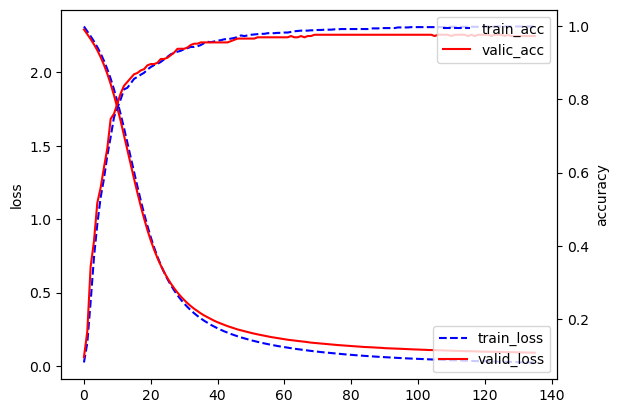

In [ ]:
import matplotlib.pyplot as plt
train_acc = [e[0] for e in trains]   # 每轮训练集准确率
valid_acc = [e[0] for e in valids]   # 每轮验证集准确率

train_loss = [e[1] for e in trains]  # 每轮训练集损失
valid_loss = [e[1] for e in valids]  # 每轮验证集损失

x = list(range(len(trains)))

# 创建一个图形框架
fig, ax1 = plt.subplots()
ax1.plot(x, train_loss, '--',color='blue', label='train_loss') # train_loss变化曲线
ax1.plot(x, valid_loss, '-', color='red', label='valid_loss') # valid_loss变化曲线
#ax1.scatter(x, valid_loss, color='red', label='valid_loss') # valid_loss变化曲线
ax1.set_ylabel('loss')

# 创建第二个Y轴
ax2 = ax1.twinx()  # 第二个 Y 轴：左轴画 loss，右轴画 accuracy，便于同图对比
ax2.plot(x, train_acc, '--', color='blue', label='train_acc') # train_acc变化曲线
ax2.plot(x, valid_acc, '-', color='red', label='valid_acc') # valid_acc变化曲线
#ax2.scatter(x, valid_acc, color='red', label='valic_acc') # valid_loss变化曲线
ax2.set_ylabel('accuracy')

# 显示图例
ax1.legend(loc='lower right')
ax2.legend(loc='upper right')

#plt.legend(['Train Loss', 'Test accuracy'], loc='upper right')
plt.xlabel('number of training examples seen')

plt.show()

##### 2.2.3.4 预测

In [ ]:
new_model = SimpleNN()  # 新建同结构模型再载入权重
new_model.load_state_dict(best_model)  # 加载最优模型
new_model = new_model.to(device)

test_acc, test_loss = run_epoch(new_model, test_loader, device, epoch, optimizer=optimizer, criterion=criterion, training=False)  # 用最优权重在测试集上评估（training=False：只前向计算）
print(f"Test Accuracy: {test_acc:.4f}.  Test Loss: {test_loss:.6f}") 

Epoch 95: 100%|██████████████████████████████████████████████████████████████████████| 6/6 [00:00<00:00, 400.22batch/s]

Test Accuracy: 0.9667.  Test Loss: 0.133067


## 3 CNN

In [59]:
import torch.nn.functional as F

class SimpleCNN(nn.Module):
    """小型 CNN：两组 [卷积-批归一化-激活-池化] + 全连接分类头，适合 8x8 小图。"""
    def __init__(self):
        super(SimpleCNN, self).__init__()

        self.conv1 = nn.Conv2d(1, 6, kernel_size=3, stride=1, padding=1, bias=True)  # 第一组卷积：1 通道输入 -> 6 个特征图；padding=1 保持 8x8 尺寸不变
        self.bn1 = nn.BatchNorm2d(num_features=6)  # 定义批量归一化层
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)      # 2x2 最大池化：尺寸减半（8->4），保留显著特征
        
        self.conv2 = nn.Conv2d(6, 16, kernel_size=3, stride=1, padding=1, bias=True)  # 第二组卷积：6 通道 -> 16 个特征图，提取更抽象的特征
        self.bn2 = nn.BatchNorm2d(num_features=16)  # 定义批量归一化层
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)   # 尺寸再减半（4->2）
        
        self.fc=nn.Sequential(  # 分类头：16 通道 x 2x2 = 64 维 -> 128 -> 10 类
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, 10)            
        )

    
    def forward(self, x):
        x = self.pool1(F.relu(self.bn1(self.conv1(x))))  # 卷积 -> 批归一化 -> ReLU 激活 -> 最大池化
        x = self.pool2(F.relu(self.bn2(self.conv2(x))))   # 同上，第二组
        x = torch.flatten(x, 1)  # 从第2维之后展平
        return self.fc(x)

In [12]:
import torch
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 加载数据集
digits = load_digits()
X, y = digits.images, digits.target  # CNN 输入用 8x8 原始图像而非展平向量
X = X.reshape(X.shape[0], 1, X.shape[1], X.shape[2])  # 注意：X的shape由[N, H, W]变成[N, 1, H, W] (N是样本数, 1是Channel数)

# X = X.repeat(3, 1)  # 纯粹是了 [N, 3, H, W]
# print(X.shape)

# 划分数据集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)  # 先分出 20% 测试集（分层抽样）
X_train, X_valid, y_train, y_valid = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)  # 再分出验证集


# 转换为 PyTorch 的 Tensor
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.int64)
X_valid_tensor = torch.tensor(X_valid, dtype=torch.float32)
y_valid_tensor = torch.tensor(y_valid, dtype=torch.int64)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.int64)

# 创建 DataSet
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
valid_dataset = TensorDataset(X_valid_tensor, y_valid_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

# 创建 DataLoader
train_loader_img = DataLoader(dataset=train_dataset, batch_size=64, shuffle=True)  # 变量名带 _img：与前面 1D 数据的 loader 区分
valid_loader_img = DataLoader(dataset=valid_dataset, batch_size=64, shuffle=True)
test_loader_img = DataLoader(dataset=test_dataset, batch_size=64, shuffle=False)  # 测试集不打乱

(1797, 3, 8, 8)


In [ ]:
import torch
import torch.nn as nn
import numpy as np
import copy
from timm.models.resnet import resnet18, resnet34
import timm

# 设置设备（GPU或CPU）
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 实例化模型
# model = SimpleCNN()

# model = resnet18()   # 直接使用rest18模型(使用的是缺省参数)
# n_classes = 10  
# model.fc = nn.Linear(model.fc.in_features, n_classes)

model = timm.create_model('resnet18', pretrained=True, num_class=10)  # 迁移学习：加载 ImageNet 预训练的 resnet18 权重，输出改为 10 类；小数据集上收敛更快、精度更高

model = model.to(device)

best_model, trains, valids = train(model, device, train_loader_img, valid_loader_img)  # 使用 CNN 专用的图像 loader 训练

Downloading: "https://download.pytorch.org/models/resnet18-5c106cde.pth" to C:\Users\HUAWEI/.cache\torch\hub\checkpoints\resnet18-5c106cde.pth
Epoch 0: 100%|████████████████████████████████████████████████████████████████████████| 5/5 [00:00<00:00, 20.06batch/s]


epoch:0. Train Accuracy: 0.2602.  Train Loss: 2.143956
epoch:0. Valid Accuracy: 0.1458.  Valid Loss: 2.250521


Epoch 9: 100%|████████████████████████████████████████████████████████████████████████| 5/5 [00:00<00:00, 19.93batch/s]


No improvement patience_count: 1


Epoch 10: 100%|███████████████████████████████████████████████████████████████████████| 5/5 [00:00<00:00, 21.88batch/s]


...

No improvement patience_count: 8


Epoch 32: 100%|███████████████████████████████████████████████████████████████████████| 5/5 [00:00<00:00, 20.54batch/s]


No improvement patience_count: 9


Epoch 33: 100%|███████████████████████████████████████████████████████████████████████| 5/5 [00:00<00:00, 24.76batch/s]

No improvement patience_count: 10
epoch:33. Train Accuracy: 0.9939.  Train Loss: 0.024097
epoch:33. Valid Accuracy: 0.9479.  Valid Loss: 0.219195
Early stopping!


## 4 作业: 
**1) 用上面的SimpleNN与SimpleCNN分别运行Mnist数据集; 2) 创建自己的NN与CNN模型，在sklearn的digits数据集上使准确率达到98%以上。**   

Mnist数据集可以算是学习深度学习最常用到的数据集。**[Mnist网站](https://yann.lecun.com/exdb/mnist/)上不但有数据集及说明同时还有许多现成的分类方法。**

这个数据集包含70000张手写数字图片，分别是60000张训练图片和10000张测试图片，训练集由来自250个不同人手写的数字构成半一般来自高中生，一半来自工作人员，测试集（test set）也是同样比例的手写数字数据，并且保证了测试集和训练集的作者不同。

每个图片都是28x28个像素点，数据集/会把一张图片的数据转成一个28x28=784的一维向量存储起来。
**下面的程序会自动下载并解压Mnist数据集文件。如果因网络问题，没有自动下载成功，也可手动[下载](www.di.ens.fr/~lelarge/MNIST.tar.gz)，并解压到"./data/MNIST"目录动下。**

In [29]:
import torch
import torchvision
import torchvision.transforms as transforms
from torchvision.datasets import MNIST

# 定义一个正规的函数来代替 lambda 函数
def reshape_image(image):
    return image.view(-1)  # 把 1x28x28 的图像张量展平成 784 维向量（供全连接网络使用）
    
transform = transforms.Compose([  # 预处理流水线：转张量 -> 归一化 -> 展平
    #transforms.Resize(32),  # 图像缩放
    transforms.ToTensor(), 
    transforms.Normalize((0.5), (0.5)),
    transforms.Lambda(reshape_image)  # 将一维张量重塑成 28x28 的二维张量（注：实际效果是展平为 784 维向量）
])

trainset = MNIST(root = './data', train=True, download=True, transform=transform)  # 下载并加载 MNIST 训练集（6 万张 28x28 手写数字）

from torch.utils.data import random_split
train_size = int(0.8 * len(trainset))
valid_size = len(trainset) - train_size
train_dataset, valid_dataset = random_split(trainset, [train_size, valid_size])  # 从训练集中划出 20% 作为验证集

train_loader = torch.utils.data.DataLoader(trainset, batch_size=64, shuffle=True)  # 注意：此处加载的仍是整个 trainset（未剔除验证集部分）
valid_loader = torch.utils.data.DataLoader(valid_dataset, batch_size=64, shuffle=True)

testset = MNIST(root = './data', train=False, download=True, transform=transform)  # 官方测试集（1 万张）用于最终评估
test_loader = torch.utils.data.DataLoader(testset, batch_size=128, shuffle=True)

In [34]:
# 设置设备（GPU或CPU）
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 实例化模型
model = SimpleNN(784, 10)  # 输入 784 维（28x28 展平），输出 10 类
model = model.to(device)

best_model, trains, valids = train(model, device, train_loader, valid_loader)  # 开始训练

Epoch 1:   0%|▎                                                                     | 4/938 [00:00<00:26, 34.99batch/s]

epoch:0. Train Accuracy: 0.8062.  Train Loss: 0.794461
epoch:0. Valid Accuracy: 0.8949.  Valid Loss: 0.380723


Epoch 11:   0%|▎                                                                    | 4/938 [00:00<00:24, 38.42batch/s]

epoch:10. Train Accuracy: 0.9634.  Train Loss: 0.127765
epoch:10. Valid Accuracy: 0.9667.  Valid Loss: 0.111688


Epoch 19:   0%|▎                                                                    | 4/938 [00:00<00:25, 37.22batch/s]

...

No improvement patience_count: 8


Epoch 96:   1%|▎                                                                    | 5/938 [00:00<00:22, 41.59batch/s]

No improvement patience_count: 9


Epoch 96: 100%|███████████████████████████████████████████████████████████████████| 188/188 [00:03<00:00, 54.18batch/s]

No improvement patience_count: 10
epoch:96. Train Accuracy: 0.9990.  Train Loss: 0.004031
epoch:96. Valid Accuracy: 1.0000.  Valid Loss: 0.000908
Early stopping!


In [28]:
examples = enumerate(test_loader)
batch_idx, (example_data, example_targets) = next(examples)  # 取出第一个 batch
print(example_targets)  # 本 batch 的真实标签
print(example_data.shape)  # [batch, 784]：每张图已被展平

tensor([5, 6, 0, 7, 7, 9, 6, 4, 8, 4, 1, 0, 5, 7, 7, 4, 9, 1, 5, 1, 8, 8, 5, 8,
        4, 3, 1, 1, 0, 6, 6, 6, 6, 1, 7, 4, 3, 7, 4, 9, 2, 7, 8, 5, 8, 5, 3, 3,
        5, 5, 0, 8, 7, 2, 6, 2, 4, 5, 3, 1, 6, 5, 3, 9, 0, 6, 0, 0, 4, 9, 8, 3,
        8, 5, 1, 7, 6, 7, 7, 8, 0, 1, 8, 9, 5, 8, 2, 5, 4, 8, 5, 5, 1, 1, 0, 4,
        0, 7, 0, 4, 5, 7, 9, 7, 0, 3, 5, 3, 2, 4, 6, 6, 2, 1, 5, 0, 0, 1, 2, 2,
        1, 2, 9, 9, 0, 6, 7, 9])
torch.Size([128, 784])


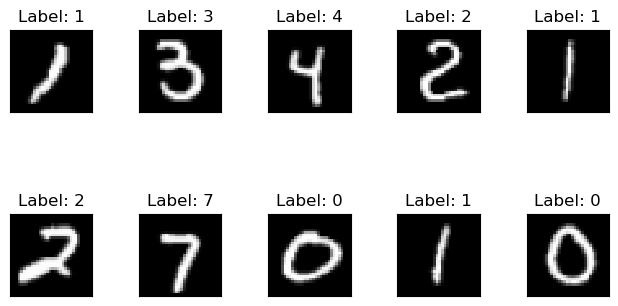

In [10]:
import matplotlib.pyplot as plt
# 可视化测试 batch 中的样本及其真实标签
fig = plt.figure()
for i in range(10):  # 前 10 个样本各画一幅子图
  plt.subplot(2,5,i+1)
  plt.tight_layout()
  plt.imshow(example_data[i][0], cmap='gray', interpolation='none')
  plt.title("Label: {}".format(example_targets[i]))
  plt.xticks([])
  plt.yticks([])
plt.show()